### Initialize instrumentation

In [1]:
# import packages
from Equipments import BNC575, Weeder, SR400, MCBOX, Andor, LeCroyScope
from Equipments.MCBOX import generate_test_voltages
from DataProcessing.Plot import PlotSaver
import numpy as np
import pyvisa
import time
import matplotlib.pyplot as plt
from scipy.signal import find_peaks

In [2]:
# set up readout and plotting
ps = PlotSaver("X:/migratedData/Rydberg_QIS/data")

In [3]:
# open list of available instruments
rm = pyvisa.ResourceManager()
print(rm.list_resources())

('ASRL1::INSTR', 'ASRL2::INSTR', 'ASRL3::INSTR', 'ASRL4::INSTR', 'ASRL5::INSTR', 'ASRL6::INSTR', 'ASRL7::INSTR', 'ASRL11::INSTR', 'GPIB0::3::INSTR', 'GPIB0::9::INSTR', 'GPIB0::23::INSTR', 'TCPIP0::169.254.110.10::inst0::INSTR', 'USB0::0x1313::0x807B::241023118::0::INSTR')


In [4]:
# connect to BNC 575 pulse generator (for controlling experimental time sequence)
bnc575 = BNC575.BNC575("GPIB0::9::INSTR")

In [5]:
# connect to WeederTech WTMCD-M driver (for 480 stepper motor)
weeder = Weeder.Weeder("ASRL1::INSTR")

In [6]:
# connect to MC USB-3114 (for compensation voltages)
mcbox = MCBOX.MCBOX(find_device = "USB-3114")

USB-3114 found.
Board number: 0


### Visualize SSFI voltage ramp

In [7]:
sample_rate = 100e+06  # 100 MSa/s
t_us = (np.arange(15_000) / sample_rate) * 1e+06  # generate time points, changed from 13,000 to 15,000

In [8]:
# desired AWG output in volts
voltage_AWG = np.interp(
    t_us,
    [0, 1, 56, 106, 146, 150],
    [0, 0, 2.75, 2.75, 0, 0],
)

# normalization; -1 corresponds to 0 V, +1 to 2.75 V
waveform = (2 * voltage_AWG / 2.75) - 1

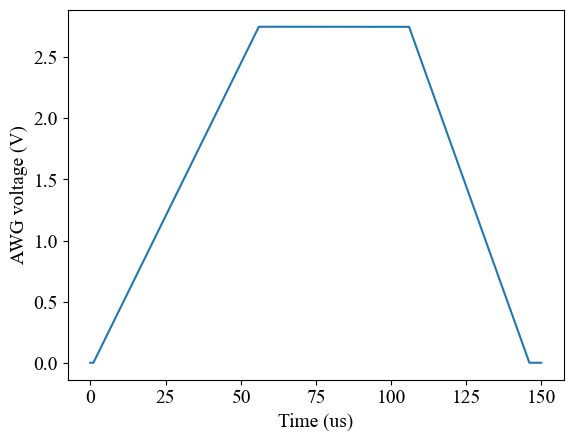

In [9]:
# plot waveform
plt.figure()
plt.plot(t_us, voltage_AWG)
plt.xlabel('Time (us)')
plt.ylabel('AWG voltage (V)')
plt.show()

### Set compensation voltages and define timing sequence, set up photon counter

In [10]:
# vset = np.array([0.04, -0.025, 0.222])
vset = np.array([0.4, -0.05, -0.015])
mcbox.set_voltage_Nchan(channels = [0,1,6,7,10,11], 
                        voltages = [0,-vset[2],vset[1],-vset[1],vset[0],-vset[0]], bipolar = True)

Channel 0 has been set to 0 V.
Channel 1 has been set to 0.015 V.
Channel 6 has been set to -0.05 V.
Channel 7 has been set to 0.05 V.
Channel 10 has been set to 0.4 V.
Channel 11 has been set to -0.4 V.
Voltages successfully set.


In [11]:
# define timing sequence

############################## current pulsed sequence ##############################
# pulse_arrangement = [["A", 1300e-6, 0, 2, 1],                 # MOT AOM
#                      [["B", 15e-6, 40e-6, 2, 1],              # 780 AOM
#                      ["C", 15e-6, 40e-6, 6, -1]],             # 480 switch
#                      [["D", 26e-6, 0, 6, 1],                  # AWG
#                      ["E", 26e-6, 0, 6, 1]],                  # SR400 gated counter
#                     ]

############################## current pulsed sequence (no counter) ################
pulse_arrangement = [["A", 1300e-6, 0, 2, 1],                 # MOT AOM
                     [["B", 15e-6, 40e-6, 2, 1],              # 780 AOM
                     ["C", 15e-6, 40e-6, 6, -1]],             # 480 switch
                     ["D", 26e-6, 0, 6, 1],                   # AWG
                    ]

# pulse_arrangement = [
#                     [["D", 26e-06, 1355e-06, 6, 1],             # AWG; ampl changed from 6 V
#                     ["E", 26e-06, 1355e-06, 6, 1]]              # gated photon counter
#                     ]
T = 1600e-6  # sequence period; changed from 1500 us

# cycle_number = 30

# photon counter gate width and delay
# gate_width = 130e-6 # changed from 20 us
# gate_delay = 3e-6  # unchanged

# notes = {"gate_width": gate_width, "gate_delay": gate_delay}
notes = {}

In [12]:
notes["bnc575 T0"] = bnc575.clock_set(period = T, mode = "CONTINUOUS")
notes["bnc575 pulses"] = bnc575.pulse_sequence_setup(pulse_arrangement)

------------------------------------------------------------
The global clock is set to:
Mode: NORM
Period: 1.60e-03s
Pulses number: N/A
------------------------------------------------------------
[['A', 0.0013, 0, 2, 1], ['B', 1.5e-05, 0.00134, 2, 1], ['C', 1.5e-05, 0.00134, 6, -1], ['D', 2.6e-05, 0.001355, 6, 1]]
------------------------------------------------------------
The channel A is set to:
Width: 1.3000e-03s
Delay: 0.0000e+00s
Synchronize to: T0
Out: 2.00

Output timers:
HGFEDCBA
00000001
------------------------------------------------------------
------------------------------------------------------------
The channel B is set to:
Width: 1.5000e-05s
Delay: 1.3400e-03s
Synchronize to: T0
Out: 2.00

Output timers:
HGFEDCBA
00000010
------------------------------------------------------------
------------------------------------------------------------
The channel C is set to:
Width: 1.5000e-05s
Delay: 1.3400e-03s
Synchronize to: T0
Out: 6.00

Output timers:
HGFEDCBA
00000100

In [13]:
bnc575.start_pulses()

### Find the Rydberg resonance

In [15]:
# find current stepper motor position
weeder.position(header = "A", query = True)

'A4400'

In [50]:
# begin stepper motor at initial position 6000, then move it out to increase the laser frequency
weeder.move("A", position = 6000, progress = True)

start at 5200 --> 6000.0 --> 6000
Old position: 5200
New position: 6000


In [ ]:
# used to move motor incrementally to zero in on the location of a resonance
weeder.advance(header = "A", num_step = 10)

### Collect oscilloscope traces

In [41]:
# connect to LeCroy 9354AM oscilloscope (for displaying DEI pulse and Rydberg counts for both states)
lecroy = LeCroyScope.LeCroyScope('GPIB0::3::INSTR', timeout = 20000)
lecroy.setup_transfer()

*IDN -> LECROY,9354AM,935403739,08.2.1



In [42]:
# collection parameters
N = 500           # number of scope sweeps averaged
V_mcp = -700.0    # MCP front voltage [V]
V_tip = 55.0      # max SSFI voltage [V]
dist = 3.0        # approximate distance between TIP and MOT [mm]
state = "69 S 1/2"  # Rydberg state under consideration (CHANGE THIS!!)

notes = {"Rydberg state": state, "Number of sweeps averaged": N, "Maximum TIP voltage (V)": V_tip,
        "MCP front voltage (V)": V_mcp, "Approximate MOT-TIP distance (mm)": dist, "Ortec connected?:": "False"}

In [43]:
# collect scope trace
t, v, info = lecroy.read_waveform("TA")
t1, v1, info1 = lecroy.read_waveform("C3")

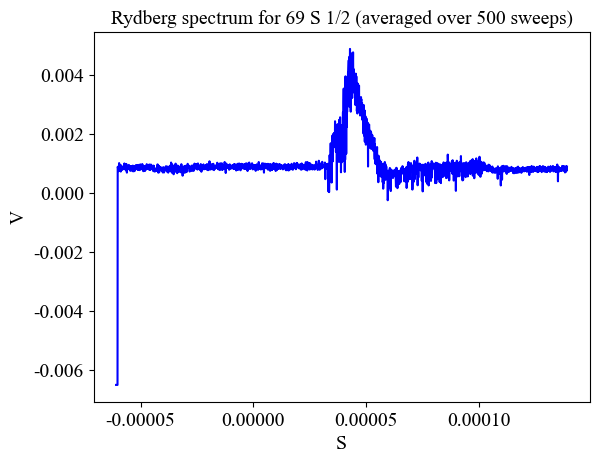

In [44]:
# plot averaged scope trace
plt.figure()
plt.title(rf'Rydberg spectrum for {state} (averaged over {N} sweeps)')
plt.plot(t, v, 'b')
plt.xlabel(info["horizontal_unit"] or "s")
plt.ylabel(info["vertical_unit"] or "V")
plt.show()

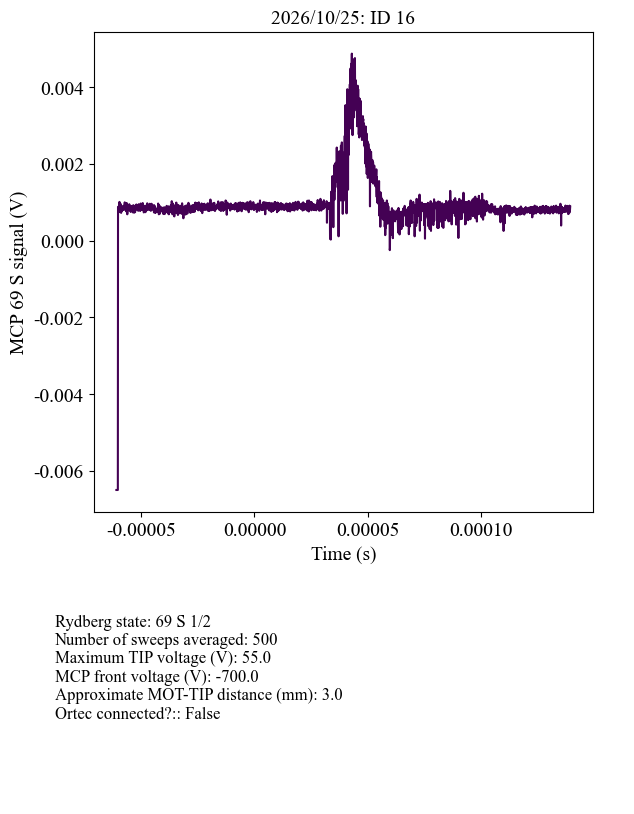

In [45]:
# save scope trace
ps.Plot2D(x = t, y = None, Z = v,
          xlabel = "Time (s)", zlabel = "MCP 69 S signal (V)", notes = notes)

In [46]:
# use for zooming into plot
def closest_idx(arr, value):
    idx = np.searchsorted(arr, value)
    idx = np.clip(idx, 1, len(arr) - 1)
    # Pick the closer of the two neighbors
    if value - arr[idx - 1] < arr[idx] - value:
        return idx - 1
    return idx

In [47]:
start, end = 30e-06, 60e-06  # CHANGE THESE !!!

i_start = closest_idx(t, start)
i_end = closest_idx(t, end)
print(i_start, i_end)

1136 1511


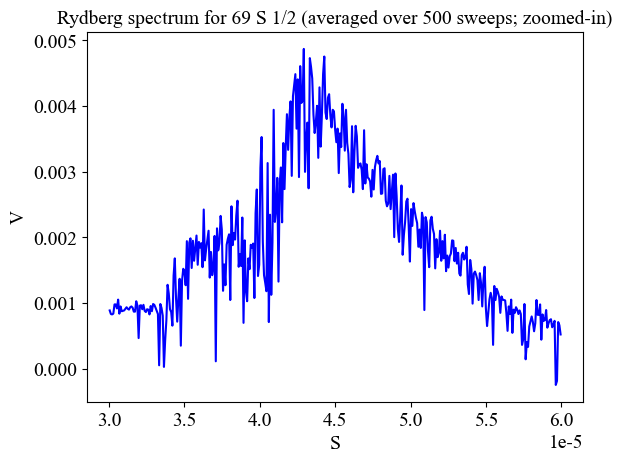

In [48]:
plt.figure()
plt.title(rf'Rydberg spectrum for {state} (averaged over {N} sweeps; zoomed-in)')
plt.plot(t[i_start:i_end], v[i_start:i_end], 'b')
plt.xlabel(info["horizontal_unit"] or "s")
plt.ylabel(info["vertical_unit"] or "V")
plt.show()

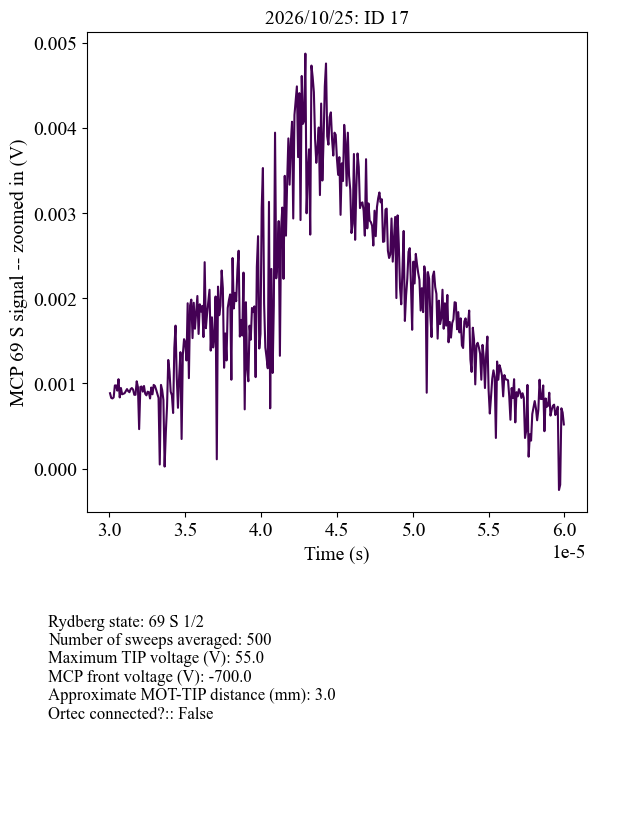

In [49]:
# save zoomed-in scope trace
ps.Plot2D(x = t[i_start:i_end], y = None, Z = v[i_start:i_end],
          xlabel = "Time (s)", zlabel = "MCP 69 S signal -- zoomed in (V)", notes = notes)

### Shut down instrumentation

In [51]:
# reset voltages to zero
vset = np.array([0.0,0.0,0.0])
mcbox.set_voltage_Nchan(channels = [0,1,6,7,10,11], 
                        voltages = [0,-vset[2],vset[1],-vset[1],vset[0],-vset[0]], bipolar = True)

Channel 0 has been set to 0 V.
Channel 1 has been set to -0.0 V.
Channel 6 has been set to 0.0 V.
Channel 7 has been set to -0.0 V.
Channel 10 has been set to 0.0 V.
Channel 11 has been set to -0.0 V.
Voltages successfully set.


In [52]:
# save current stepper motor position
weeder.save(header = "A", query = True)

'saving complete.'

In [ ]:
# OPTIONAL: disables pulses from BNC box 
# (can also be done by pressing RUN/STOP button or individual channel buttons on device)
bnc575.disable_all()

In [ ]:
# OPTIONAL: disarms the pulse generator 
# (can also be done by pressing RUN/STOP button on device)
bnc575.disarm_all()

In [ ]:
# disconnect from pulse generator
bnc575.pyvisa.close()

In [ ]:
# disconnect from SRS photon counter
sr400.pyvisa.close()

In [ ]:
# disconnect from oscillscope
lecroy.close()